In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, balanced_accuracy_score, recall_score

# Load the merged dataset stored locally in the notebooks folder
final_data = pd.read_csv("final_merged_data.csv")

# Check that it loaded correctly
final_data.shape

(392, 94)

## With original data

In [82]:
# Make copy that will be modified for use in analysis
df = final_data.copy()

# Identify each unique physical truck
df["Truck_ID"] = (
    df["Car"].astype(str) + "_" +
    df["Truck"].astype(str)
)
# list of features that will be used for RF
features = [
    "Eq Con 3mm",
    "Flange Width (Sd)_L",
    "Flange Width (Sd)_R",
    "Flange Height (Sh)_L",
    "Flange Height (Sh)_R",
    "Max Hollow Wear_L",
    "Max Hollow Wear_R",
    "Max Hollow Wear Position_L",
    "Max Hollow Wear Position_R",
    "Flange Radius_L",
    "Flange Radius_R"
]

# Confirm that target labels agree within each truck-rail group
group_cols = ["Truck_ID", "Rail_Profile"]

assert (
    df.groupby(group_cols)["Empty_Truck_Hunted"]
      .nunique(dropna=False)
      .eq(1).all()
), "Inconsistent hunting labels within truck-rail groups"

# Aggregate measurements from both axles
truck_df = (
    df.groupby(group_cols)
      .agg(
          {**{feature: "mean" for feature in features},
           "Empty_Truck_Hunted": "first"}
      )
      .reset_index()
)

In [83]:
# Add rail profile as a categorical predictor
X = truck_df[features + ["Rail_Profile"]].copy()
X = pd.get_dummies(
    X, columns=["Rail_Profile"], dtype=int
)

y = truck_df["Empty_Truck_Hunted"]
groups = truck_df["Truck_ID"]

print("Class distribution:")
print(y.value_counts())

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

# Out-of-fold predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    groups=groups
)

print(classification_report(y, y_pred, zero_division=0))
print(confusion_matrix(y, y_pred))

# Save model's values for use in visual
original_y = y.copy()
original_pred = y_pred.copy()
original_keys = truck_df.loc[
    y.index, ["Truck_ID", "Rail_Profile"]
].reset_index(drop=True)

Class distribution:
Empty_Truck_Hunted
True     126
False     70
Name: count, dtype: int64
              precision    recall  f1-score   support

       False       0.51      0.53      0.52        70
        True       0.73      0.72      0.73       126

    accuracy                           0.65       196
   macro avg       0.62      0.63      0.62       196
weighted avg       0.66      0.65      0.65       196

[[37 33]
 [35 91]]


The classification report returned an accuracy score of 65%, hunting a 52% of not occurring and a 73% of occurring when using the conicity, flange measurements, and max hollow wear features. These features were used in this RF classifier because flange measurements were a common occurance in other data models created.

## With the added average features

Created averages and differences for the hollow wear and flange measurements for testing. Implemented this to test if there is a good significance on the outcome of the RF classifier's scores.

In [84]:
# Create wheelset hollow wear features from the left and right wheels
final_data["Hollow_Wear_Avg"] = (
    final_data["Max Hollow Wear - AAR_L"] +
    final_data["Max Hollow Wear - AAR_R"]
) / 2

final_data["Hollow_Wear_Diff"] = abs(
    final_data["Max Hollow Wear - AAR_L"] -
    final_data["Max Hollow Wear - AAR_R"]
)

# Create wheelset qR features from the left and right wheels
final_data["qR_Avg"] = (
    final_data["qR_L"] +
    final_data["qR_R"]
) / 2

final_data["qR_Diff"] = abs(
    final_data["qR_L"] -
    final_data["qR_R"]
)

# Create wheelset flange width features from the left and right wheels
final_data["Flange_Width_Avg"] = (
    final_data["Flange Width_L"] +
    final_data["Flange Width_R"]
) / 2

final_data["Flange_Width_Diff"] = abs(
    final_data["Flange Width_L"] -
    final_data["Flange Width_R"]
)

# Create wheelset maximum flange angle features
final_data["Flange_Angle_Avg"] = (
    final_data["Max Flange Angle_L"] +
    final_data["Max Flange Angle_R"]
) / 2

final_data["Flange_Angle_Diff"] = abs(
    final_data["Max Flange Angle_L"] -
    final_data["Max Flange Angle_R"]
)

# Create wheelset averages for the main wheel wear measurements
measurements = [
    "Flange Width (Sd)",
    "Flange Height (Sh)",
    "qR",
    "Flange Width",
    "Max Hollow Wear",
    "Flange Radius",
    "Max Flange Angle",
    "Min Flange Root Radius",
    "Max Hollow Wear - AAR"
]

for measurement in measurements:
    final_data[measurement + "_Avg"] = (
        final_data[measurement + "_L"] +
        final_data[measurement + "_R"]
    ) / 2

print("Dataset shape:", final_data.shape)

Dataset shape: (392, 110)


C:\Users\aaron\AppData\Local\Temp\ipykernel_29860\4239710233.py:59: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  final_data[measurement + "_Avg"] = (


In [85]:
# Make a copy for the Random Forest analysis
# Axles 1-2 belong to Truck 1; axles 3-4 belong to Truck 2.
truck_df = final_data.copy()

truck_df["Truck_ID"] = (
    truck_df["Car"].astype(str) + "_" + truck_df["Truck"].astype(str)
)

# Original wheel geometry and wheel-rail interaction predictors
features = [
    "Eq Con 3mm",
    "Flange Width (Sd)_L", "Flange Width (Sd)_R",
    "Flange Height (Sh)_L", "Flange Height (Sh)_R",
    "Max Hollow Wear_L", "Max Hollow Wear_R",
    "Max Hollow Wear Position_L", "Max Hollow Wear Position_R",
    "Flange Radius_L", "Flange Radius_R", 
    "Hollow_Wear_Avg", "Hollow_Wear_Diff",
    "qR_Avg", "qR_Diff",
    "Flange_Width_Avg", "Flange_Width_Diff",
    "Flange_Angle_Avg", "Flange_Angle_Diff",
    "Flange Width (Sd)_Avg",
    "Flange Height (Sh)_Avg",
    "Max Hollow Wear_Avg",
    "Flange Radius_Avg",
    "Min Flange Root Radius_Avg"
]

group_cols = ["Truck_ID", "Rail_Profile"]

# Confirm hunting outcomes agree across the two axles
assert (
    truck_df.groupby(group_cols)["Empty_Truck_Hunted"]
    .nunique(dropna=False).eq(1).all()
)

truck_df = (
    truck_df.groupby(group_cols)
    .agg({
        **{feature: "mean" for feature in features},
        "Empty_Truck_Hunted": "first"
    })
    .reset_index()
)

In [86]:
# Add rail profile as a categorical predictor
X = truck_df[features + ["Rail_Profile"]].copy()
X = pd.get_dummies(
    X, columns=["Rail_Profile"], dtype=int
)

y = truck_df["Empty_Truck_Hunted"]
groups = truck_df["Truck_ID"]

print("Class distribution:")
print(y.value_counts())

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=4,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=5)

# Out-of-fold predictions
y_pred = cross_val_predict(
    model,
    X,
    y,
    cv=cv,
    groups=groups
)

print(classification_report(y, y_pred, zero_division=0))
print(confusion_matrix(y, y_pred))

# Save the new model's values for use in the visual
engineered_y = y.copy()
engineered_pred = y_pred.copy()
engineered_keys = truck_df.loc[
    y.index, ["Truck_ID", "Rail_Profile"]
].reset_index(drop=True)

assert original_keys.equals(engineered_keys)
assert np.array_equal(original_y, engineered_y)

Class distribution:
Empty_Truck_Hunted
True     126
False     70
Name: count, dtype: int64
              precision    recall  f1-score   support

       False       0.47      0.47      0.47        70
        True       0.71      0.71      0.71       126

    accuracy                           0.62       196
   macro avg       0.59      0.59      0.59       196
weighted avg       0.62      0.62      0.62       196

[[33 37]
 [37 89]]


Implementing the averages slightly reduced the accuracy score to 62%, hunting a 47% of not occuring, and a 71% of occuring. The averages made the RF classifer worse as the values were lower and there were no significant differences between precision, recall and f1-score.

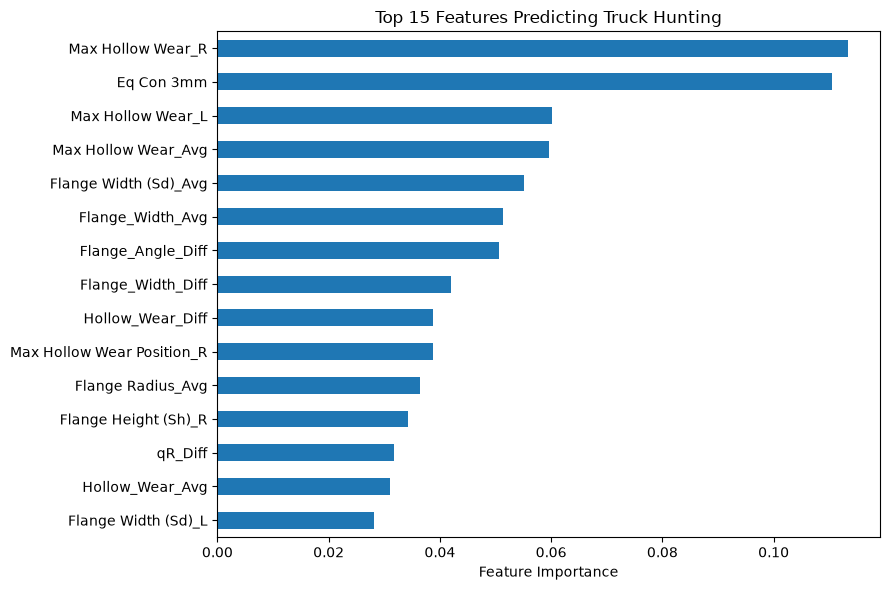

In [87]:
model.fit(X, y)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.xlabel("Feature Importance")
plt.title("Top 15 Features Predicting Truck Hunting")
plt.tight_layout()
plt.show()


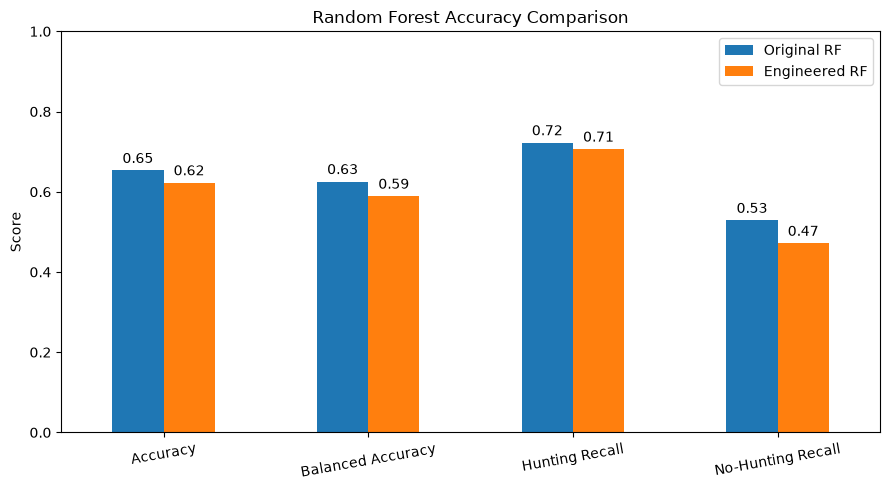

In [88]:
def get_scores(y, pred):
    return [
        accuracy_score(y, pred),
        balanced_accuracy_score(y, pred),
        recall_score(y, pred, pos_label=True),
        recall_score(y, pred, pos_label=False)
    ]

comparison = pd.DataFrame({
    "Original RF": get_scores(original_y, original_pred),
    "Engineered RF": get_scores(engineered_y, engineered_pred)
}, index=[
    "Accuracy",
    "Balanced Accuracy",
    "Hunting Recall",
    "No-Hunting Recall"
])

ax = comparison.plot(kind="bar", figsize=(9, 5))

# Add values above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
    
plt.title("Random Forest Accuracy Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


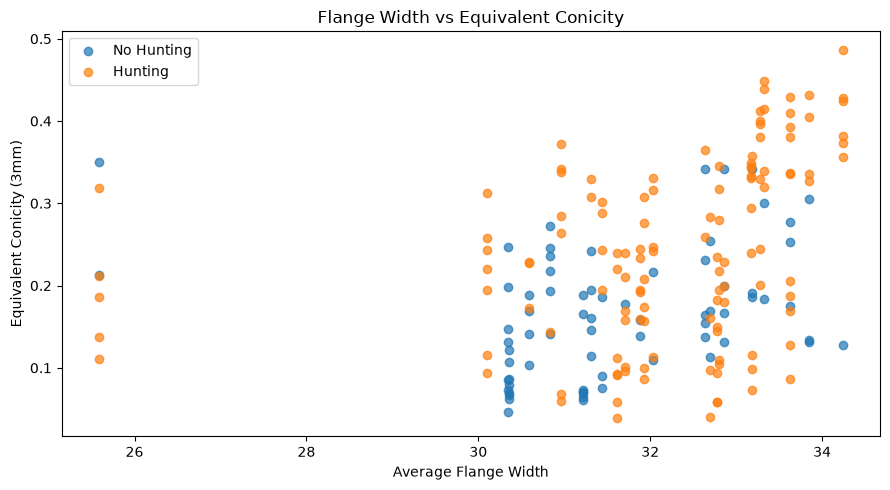

In [89]:
plot_df = truck_df.copy()

# Average left and right flange width
plot_df["Flange_Mean"] = (
    plot_df["Flange Width (Sd)_L"] +
    plot_df["Flange Width (Sd)_R"]
) / 2

plt.figure(figsize=(9, 5))

for hunted, label in [(False, "No Hunting"), (True, "Hunting")]:
    subset = plot_df[
        plot_df["Empty_Truck_Hunted"] == hunted
    ]

    plt.scatter(
        subset["Flange_Mean"],
        subset["Eq Con 3mm"],
        label=label,
        alpha=0.7
    )

plt.xlabel("Average Flange Width")
plt.ylabel("Equivalent Conicity (3mm)")
plt.title("Flange Width vs Equivalent Conicity")
plt.legend()
plt.tight_layout()
plt.show()

Visually showcases hunting occurances between different flange widths and conicity, however, conicity also depends on the rail profile.